In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import  ImageFolder
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [ ]:
transform = transforms. Compose(
    [transforms.RandomCrop(32 , padding=4),
     transforms.RandomHorizontalFlip(),
     transforms.ToTensor(),
     transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))])
batch_size = 32

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    download=True,
    transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(testset,
                                         batch_size=batch_size,
                                         shuffle=False,
                                         num_workers=2)

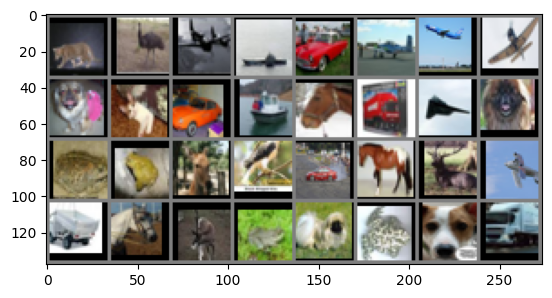

In [ ]:
def imshow(img):
  img = img / 2+0.5
  npimg = img.numpy()
  plt.imshow(np.transpose(npimg,(1,2,0)))
  plt.show()

dataiter = iter(trainloader)
images , labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))

In [ ]:
class Net(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels=3,
                           out_channels=6,
                           kernel_size=5)
    self.pool = nn.MaxPool2d(2,2)
    self.conv2 = nn.Conv2d(in_channels=6,
                           out_channels=16,
                           kernel_size=5)
    self.pool = nn.MaxPool2d(2,2)
    self.conv3 = nn.Conv2d(in_channels=6,
                           out_channels=16,
                           kernel_size=5)
    self.fc1 = nn.Linear(16 *5*5 , 120)
    self.fc2 = nn.Linear(120,84)
    self.fc3 = nn.Linear(84 ,10)

  def forward(self ,x):
    x = self.pool(F.relu(self.conv1(x)))
    x = self.pool(F.relu(self.conv2(x)))
    x = torch.flatten(x ,1)
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return x
net = Net()
net = net.to(device)


In [ ]:
print(outputs[0])
print(labels[0])

tensor([-1.6405, -3.2390, -0.5472, -0.3682, -0.8002,  0.6812, -4.6922, -0.2120,
         0.1726,  0.9006], device='cuda:0')
tensor(3)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(),lr=0.001)

for epoch in range(16):
  running_loss = 0.0
  for i , data in enumerate(trainloader , 0):
    inputs , labels = data[0].to(device) , data[1].to(device)
    optimizer.zero_grad()
    outputs = net(inputs)
    loss = criterion(outputs , labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item()
    if i % 2000 == 1999:
      print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
      running_loss = 0.0

print('Finished Training')


Finished Training


In [ ]:
correct = 0
total = 0
with torch.no_grad():
  for data in testloader:
    images , labels = data[0].to(device),data[1].to(device)
    outputs = net(images)
    preds = torch.max(outputs , 1)[1]
    total += labels.size(0)
    correct += (preds == labels).sum().item()
print(f'Accuracy of the network on the 10000 test images: {100 * correct / total} %')

Accuracy of the network on the 10000 test images: 62.336 %
